In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import pickle

import pandas as pd
from benchmark_func import params_search, print_summary, run_benchmark, show_graph

from algorithms.baseline import UserBasedCF
from algorithms.implicit_als import ImplicitALS
from utils.data_load import load_dataset, make_subset, save_df, split_train_test_by_time
from utils.data_stats import dataframe_stats

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
pd.set_option("display.max_columns", 25)

In [ ]:
DATA_PATH = "../data/raw/ratings.csv"

DATA_TRAIN_1M_PATH = "../data/processed/train_1M.csv"
DATA_VAL_1M_PATH = "../data/processed/val_1M.csv"
DATA_TEST_1M_PATH = "../data/processed/test_1M.csv"

DATA_TRAIN_10M_PATH = "../data/processed/train_10M.csv"
DATA_VAL_10M_PATH = "../data/processed/val_10M.csv"
DATA_TEST_10M_PATH = "../data/processed/test_10M.csv"

DATA_TRAIN_32M_PATH = "../data/processed/train_32M.csv"
DATA_VAL_32M_PATH = "../data/processed/val_32M.csv"
DATA_TEST_32M_PATH = "../data/processed/test_32M.csv"

N_RUNS = 3

USERBASED_CF_PARAMS_SEARCH_PATH = "../data/processed/df_UserBasedCF_2.pkl"
IMPLICIT_ALS_PARAMS_SEARCH_PATH = "../data/processed/df_ImplicitALS_2.pkl"

In [5]:
df = load_dataset(path=DATA_PATH)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 976.6 MB


In [6]:
df.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [7]:
try:
    train = load_dataset(DATA_TRAIN_1M_PATH)
    val = load_dataset(DATA_VAL_1M_PATH)
    test = load_dataset(DATA_TEST_1M_PATH)
except FileNotFoundError:
    subset = make_subset(df=df, n_ratings=1_000_000)
    train_val, test = split_train_test_by_time(subset, test_frac=0.2)
    train, val = split_train_test_by_time(train_val, test_frac=0.125)
    save_df(df=train, path=DATA_TRAIN_1M_PATH)
    save_df(df=val, path=DATA_VAL_1M_PATH)
    save_df(df=test, path=DATA_TEST_1M_PATH)

print(train.shape, val.shape, test.shape)

(700135, 4) (99921, 4) (199960, 4)


In [8]:
train.describe()

,userId,movieId,rating,timestamp
count,700135.000000,700135.000000,700135.000000,7.001350e+05
mean,99191.717673,25537.721149,3.579263,1.268655e+09
std,58380.642285,45573.005045,1.051947,2.541866e+08
min,10.000000,1.000000,0.500000,8.253600e+08
25%,48911.000000,1200.000000,3.000000,1.042391e+09
50%,98122.000000,3033.000000,4.000000,1.269987e+09
75%,150569.000000,32587.000000,4.000000,1.493711e+09
max,200935.000000,291803.000000,5.000000,1.696869e+09


In [9]:
val.describe()

,userId,movieId,rating,timestamp
count,99921.000000,99921.000000,99921.000000,9.992100e+04
mean,99189.740345,33998.187668,3.466944,1.288774e+09
std,58376.697991,54428.433186,1.055431,2.562579e+08
min,10.000000,1.000000,0.500000,8.256384e+08
25%,48911.000000,1339.000000,3.000000,1.066187e+09
50%,98100.000000,3996.000000,3.500000,1.306351e+09
75%,150569.000000,54270.000000,4.000000,1.515867e+09
max,200935.000000,288513.000000,5.000000,1.696869e+09


In [10]:
test.describe()

,userId,movieId,rating,timestamp
count,199960.000000,199960.000000,199960.000000,1.999600e+05
mean,99188.357041,41039.464603,3.473062,1.307114e+09
std,58381.433520,64470.101002,1.057868,2.639991e+08
min,10.000000,1.000000,0.500000,8.256384e+08
25%,48911.000000,1419.000000,3.000000,1.078707e+09
50%,98122.000000,4427.500000,3.500000,1.334686e+09
75%,150574.000000,63859.000000,4.000000,1.546718e+09
max,200935.000000,291807.000000,5.000000,1.697158e+09


In [11]:
stats = pd.concat(
    {
        "train_1M": dataframe_stats(df=load_dataset(DATA_TRAIN_1M_PATH)),
        "val_1M":  dataframe_stats(df=load_dataset(DATA_VAL_1M_PATH)),
        "test_1M":  dataframe_stats(df=load_dataset(DATA_TEST_1M_PATH)),
        "train_10M": dataframe_stats(df=load_dataset(DATA_TRAIN_10M_PATH)),
        "val_10M":  dataframe_stats(df=load_dataset(DATA_VAL_10M_PATH)),
        "test_10M":  dataframe_stats(df=load_dataset(DATA_TEST_10M_PATH)),
        "train_32M": dataframe_stats(df=load_dataset(DATA_TRAIN_32M_PATH)),
        "val_32M":  dataframe_stats(df=load_dataset(DATA_VAL_32M_PATH)),
        "test_32M":  dataframe_stats(df=load_dataset(DATA_TEST_32M_PATH)),
    },
    names=["subset_split"],
).reset_index(level="subset_split")

stats

,subset_split,n_users,n_items,n_ratings,density,sparsity,user_ratings_median,user_ratings_p95,user_ratings_max,item_ratings_median,item_ratings_p95,item_ratings_max,frac_users_lt_5,frac_items_lt_5,frac_ratings_ge_3.5,df_memory_mb,rating_mean,rating_std,rating_min,rating_max,rating_median
0,train_1M,6373,20440,700135,0.005375,0.994625,52.0,394.0,3954,3.0,167.00,2854,0.000000,0.599266,0.647119,21.366550,3.579263,1.051947,0.5,5.0,4.0
0,val_1M,6373,12610,99921,0.001243,0.998757,7.0,56.0,565,2.0,37.00,201,0.322925,0.681285,0.610863,3.049473,3.466944,1.055431,0.5,5.0,3.5
0,test_1M,6373,17425,199960,0.001801,0.998199,15.0,112.4,1130,2.0,56.00,294,0.063706,0.641836,0.614738,6.102421,3.473062,1.057868,0.5,5.0,3.5
0,train_10M,62946,46788,7001294,0.002377,0.997623,51.0,398.0,6311,3.0,541.65,28635,0.000000,0.569740,0.642551,213.662663,3.573083,1.051692,0.5,5.0,4.0
0,val_10M,62946,30999,999099,0.000512,0.999488,7.0,57.0,902,2.0,168.00,1811,0.333143,0.616697,0.611499,30.490208,3.475512,1.049316,0.5,5.0,3.5
0,test_10M,62946,44435,1999637,0.000715,0.999285,14.0,114.0,1803,2.0,229.00,3060,0.066311,0.614583,0.616517,61.024204,3.481425,1.047734,0.5,5.0,3.5
0,train_32M,200948,65583,22403910,0.001700,0.998300,51.0,400.0,23333,4.0,1020.00,91080,0.000000,0.507342,0.640847,683.713200,3.569123,1.059275,0.5,5.0,4.0
0,val_32M,200948,47984,3197329,0.000332,0.999668,7.0,57.0,3333,3.0,311.00,5829,0.331190,0.602013,0.609419,97.574863,3.471042,1.055535,0.5,5.0,3.5
0,test_32M,200948,68517,6398965,0.000465,0.999535,15.0,114.0,6666,3.0,408.00,9775,0.065619,0.587227,0.612965,195.281040,3.474468,1.055137,0.5,5.0,3.5


In [12]:
def model_factory():
    return UserBasedCF(top_k=20)

results = run_benchmark(model_factory, train, val, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF(top_k=20): 2.509 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1164.535 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 5.643 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 498.277 MB
[timer] Обучение UserBasedCF(top_k=20): 2.572 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1150.668 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 5.620 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 497.145 MB
[timer] Обучение UserBasedCF(top_k=20): 2.425 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1149.398 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 5.699 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 496.941 MB
Модель UserBasedCF
Среднее train_time 2.502161184946696
Среднее pred_time 5.653996864954631
Средний прирост RSS процесса при обучении: 1154.867 MB
Средний пиковый RSS процесса при обучении: 2367.214 MB
Средний прирост RSS процесса при прогнозе: 497.454 MB
Средний пиковый RSS п

Подбор гиперпараметров для базовой модели `UserBasedCF`

In [13]:
df_UserBasedCF = params_search(
    model_factory=lambda **kw: UserBasedCF(**kw),
    train=train,
    test=val,
    params={"top_k": [5, 10, 15, 20, 30, 50, 100]},
    n_runs=N_RUNS,
)

with open(USERBASED_CF_PARAMS_SEARCH_PATH, "wb") as f:
    pickle.dump(df_UserBasedCF, f)

[timer] Обучение UserBasedCF(top_k=5): 2.481 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1149.137 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.913 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 496.961 MB
[timer] Обучение UserBasedCF(top_k=5): 2.430 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1148.809 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.794 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 496.949 MB
[timer] Обучение UserBasedCF(top_k=5): 2.660 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1149.277 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.673 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 496.941 MB
[timer] Обучение UserBasedCF(top_k=10): 2.721 сек.
[memory_usage] Обучение UserBasedCF(top_k=10): 1149.449 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=10): 3.805 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=10): 496.941 MB
[timer] Обучение UserBasedCF(top_k=10): 2.577 се

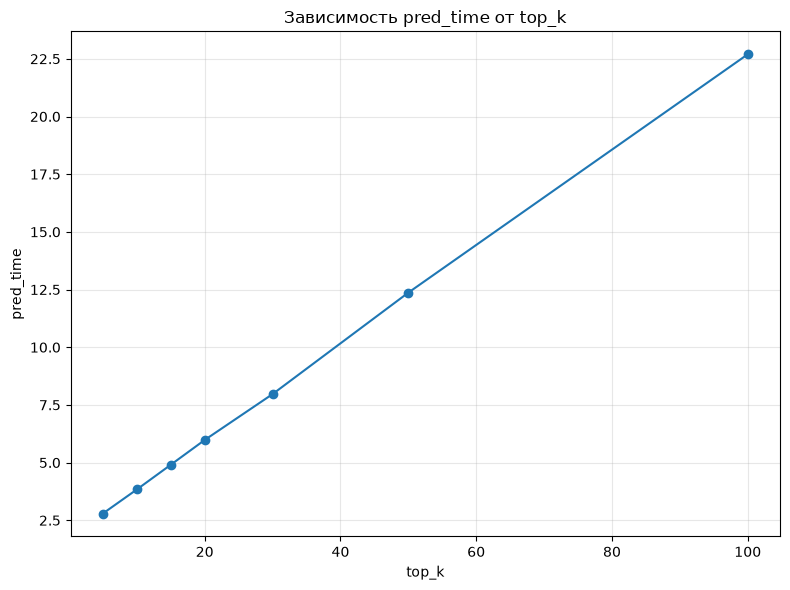

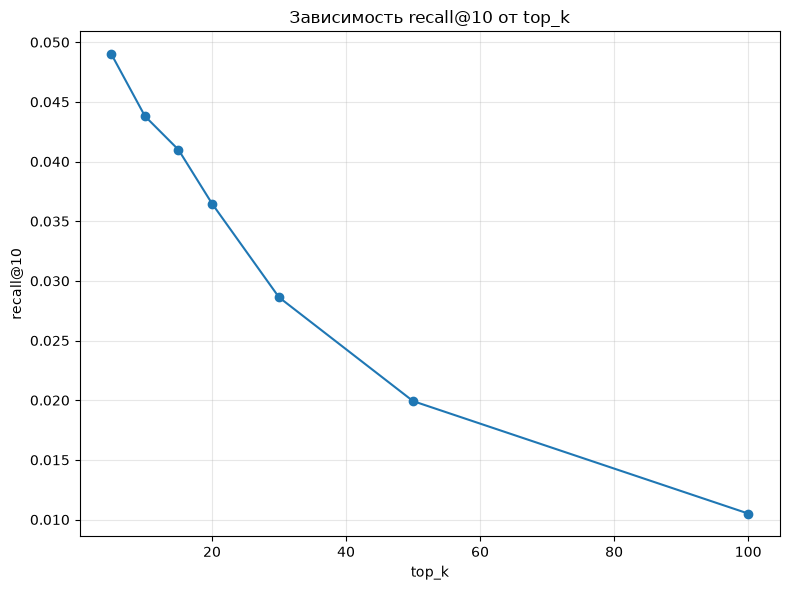

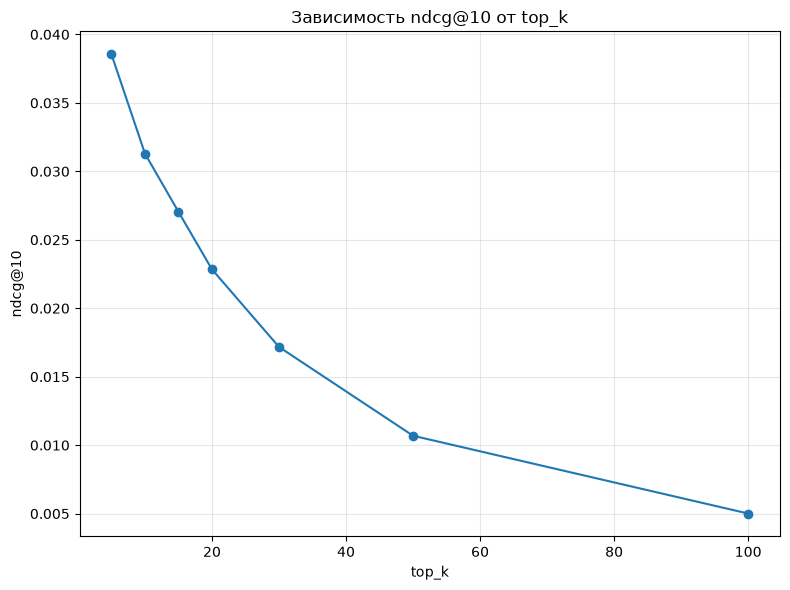

In [14]:
with open(USERBASED_CF_PARAMS_SEARCH_PATH, "rb") as f:
    df_UserBasedCF = pickle.load(f)

show_graph(
    results_df=df_UserBasedCF,
    params=["top_k"],
    metrics=["pred_time", "recall@10", "ndcg@10"],
    save_dir="graphs/UserBasedCF",
)

In [21]:
with open(USERBASED_CF_PARAMS_SEARCH_PATH, "rb") as f:
    df_UserBasedCF = pickle.load(f)

df_UserBasedCF

,top_k,train_time,pred_time,train_mem_delta,train_mem_peak,pred_mem_delta,pred_mem_peak,recall@10,ndcg@10
0,5,2.523811,2.793381,1149.074219,2369.618490,496.950521,2369.618490,0.048986,0.038549
1,10,2.694782,3.835043,1149.087240,2371.019531,496.941406,2371.019531,0.043802,0.031296
2,15,2.526456,4.906044,1148.968750,2371.613281,496.932292,2371.613281,0.040988,0.027043
3,20,2.551082,5.980726,1148.937500,2372.274740,496.941406,2372.274740,0.036481,0.022839
4,30,2.489949,7.969235,1148.756510,2372.458333,496.949219,2372.458333,0.028623,0.017174
5,50,2.484936,12.366712,1148.851562,2372.567708,496.942708,2372.567708,0.019926,0.010689
6,100,2.503266,22.696075,1148.708333,2372.722656,496.949219,2372.722656,0.010506,0.005007


In [15]:
def model_factory():
    return UserBasedCF(top_k=5)

train_val = pd.concat([train, val], ignore_index=True)

results = run_benchmark(model_factory, train_val, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF(top_k=5): 2.696 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1260.684 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.972 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 552.398 MB
[timer] Обучение UserBasedCF(top_k=5): 2.575 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1261.152 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 3.066 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 551.762 MB
[timer] Обучение UserBasedCF(top_k=5): 2.516 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1261.012 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.924 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 552.262 MB
Модель UserBasedCF
Среднее train_time 2.595581531524658
Среднее pred_time 2.9876402219136557
Средний прирост RSS процесса при обучении: 1260.949 MB
Средний пиковый RSS процесса при обучении: 2511.806 MB
Средний прирост RSS процесса при прогнозе: 552.141 MB
Средний пиковый RSS процесса при

Таким образом, лучший `top_k=5`:

- при `top_k=5` - самые похожие пользователи, у которых много общих фильмов;
- при `top_k=100` - все, у кого есть хоть 1 общий, включая почти случайных;
- меньше - лучше, потому что сигнал чище.

memory-based CF деградирует при добавлении соседей, потому что нет достаточного числа действительно похожих пользователей.

In [16]:
def model_factory():
    return ImplicitALS(factors=64, iterations=20, regularization=0.05, alpha=40.0)

results = run_benchmark(model_factory, train, val, n_runs=N_RUNS)

print_summary(results)

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.825 сек.
[memory_usage] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 62.152 MB
[timer] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 1.757 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.141 MB
[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.778 сек.
[memory_usage] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 61.586 MB
[timer] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 1.830 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.027 MB
[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.758 сек.
[memory_usage] О

Чтобы проверить влияние размерности скрытого пространства на смещение в сторону популярных объектов, была посчитана средняя популярность рекомендованных фильмов (среднее число оценок фильма в train) при фиксированных `iterations=40`, `regularization=0.2` и `alpha=10`

In [24]:
item_pop = train["movieId"].value_counts().to_dict()
val_users = val["userId"].unique().tolist()

for f in [16, 32, 64, 128, 256]:
    model = ImplicitALS(factors=f, iterations=40, regularization=0.2, alpha=10.0)
    model.fit(train)
    recs = model.recommend(val_users, n=10)
    
    all_rec_items = [item for items in recs.values() for item in items]
    mean_pop = sum(item_pop.get(i, 0) for i in all_rec_items) / len(all_rec_items)
    print(f"factors={f}: средняя популярность в топ-10 = {mean_pop:.1f} оценок")

factors=16: средняя популярность в топ-10 = 1089.6 оценок
factors=32: средняя популярность в топ-10 = 959.2 оценок
factors=64: средняя популярность в топ-10 = 937.5 оценок
factors=128: средняя популярность в топ-10 = 974.1 оценок
factors=256: средняя популярность в топ-10 = 753.8 оценок


Таким образом, с увеличением factors смещение в сторону популярных фильмов нельзя считать основной причиной роста NDCG@10

In [18]:
df_ImplicitALS = params_search(
    model_factory=lambda **kw: ImplicitALS(**kw),
    train=train,
    test=val,
    params={
        "factors": [16, 32, 64, 128],
        "iterations": [10, 20, 30, 40],
        "regularization": [0.01, 0.05, 0.1, 0.2, 0.5],
        "alpha": [10.0, 20.0, 40.0, 80.0],
    },
    n_runs=N_RUNS,
)

with open(IMPLICIT_ALS_PARAMS_SEARCH_PATH, "wb") as f:
    pickle.dump(df_ImplicitALS, f)

[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.378 сек.
[memory_usage] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 56.504 MB
[timer] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 1.062 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 1.008 MB
[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.377 сек.
[memory_usage] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 55.254 MB
[timer] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 1.084 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.020 MB
[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.370 сек.
[memory_usage] О

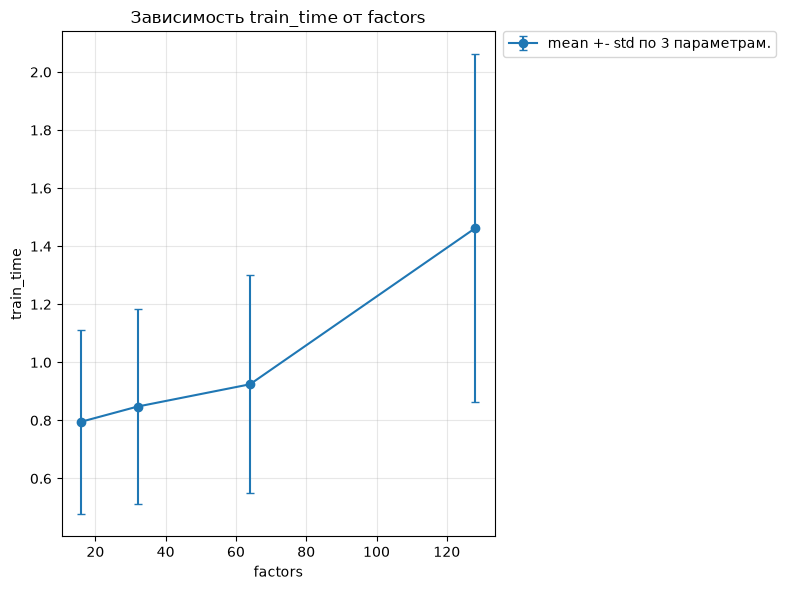

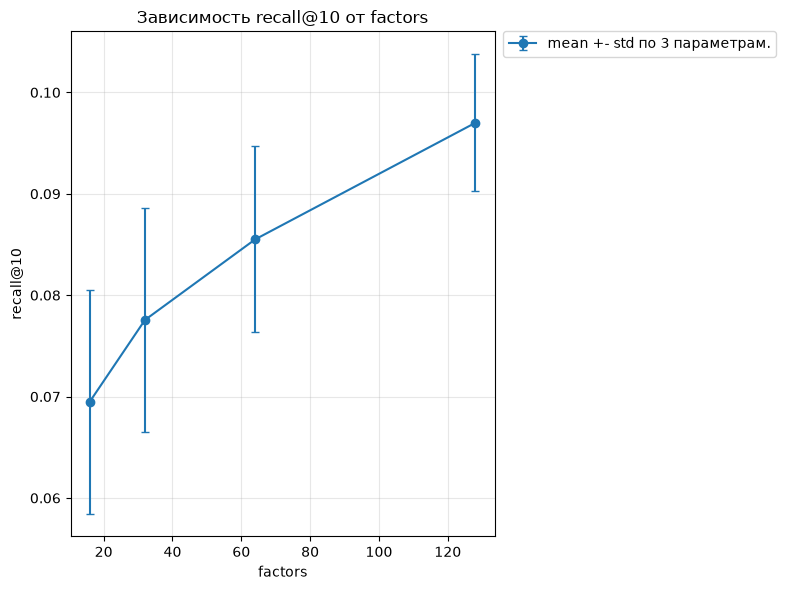

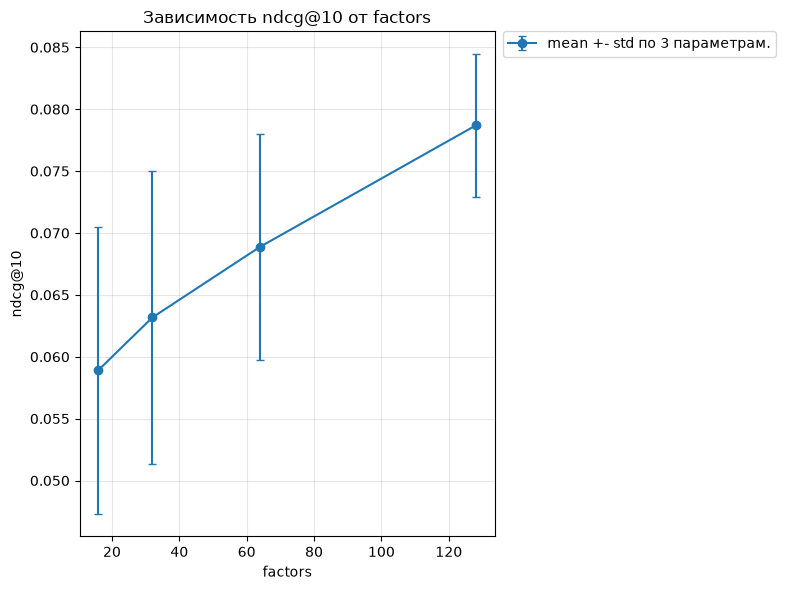

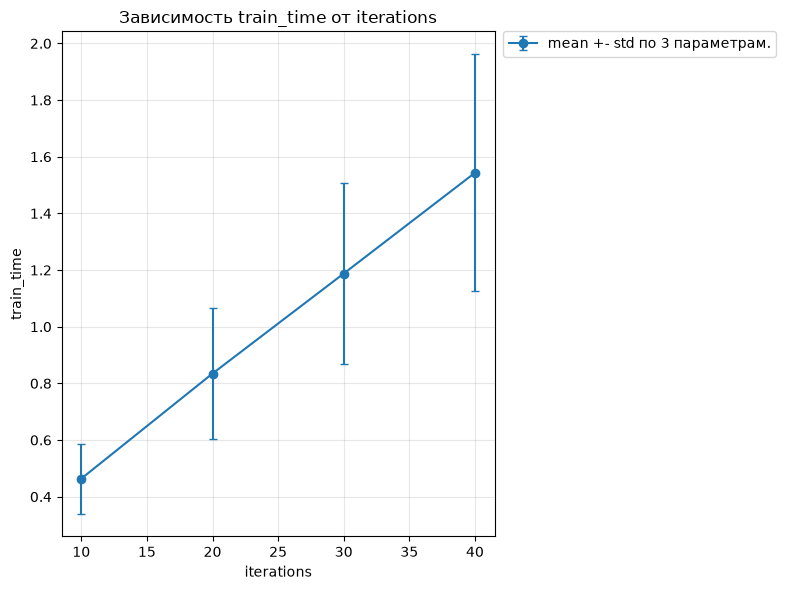

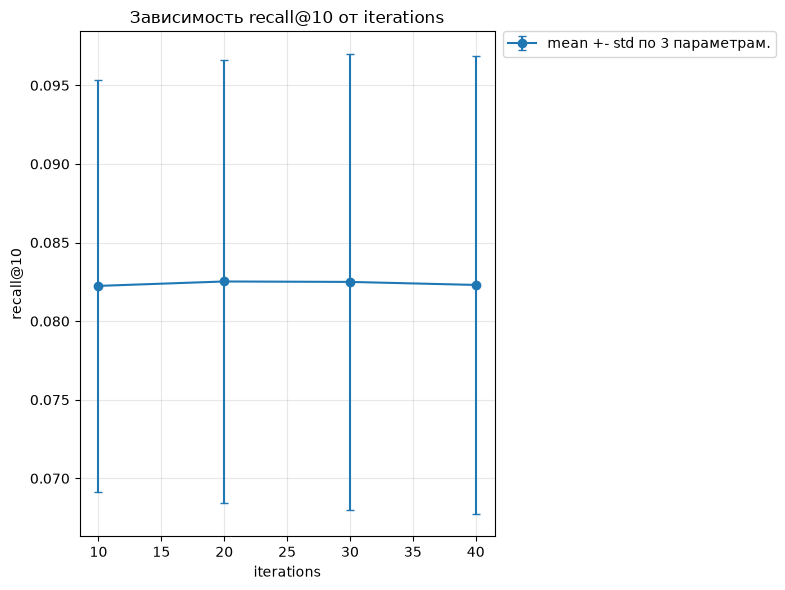

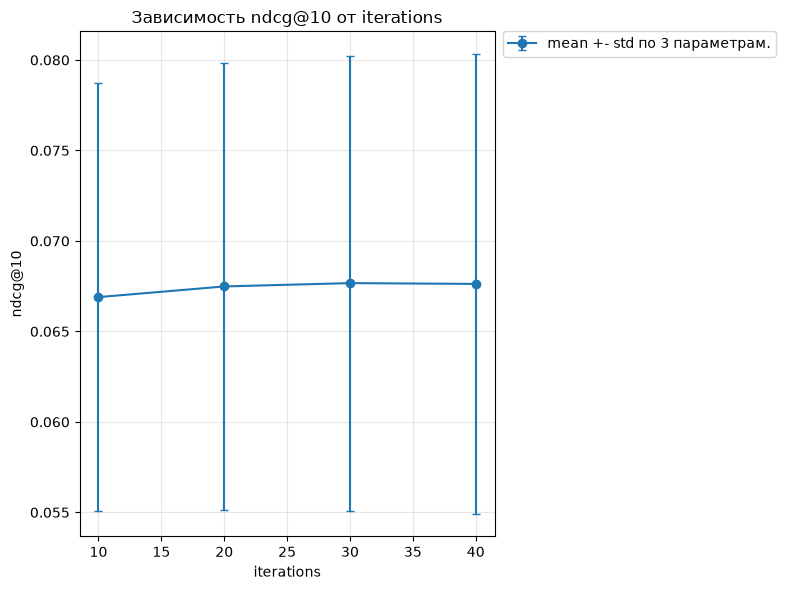

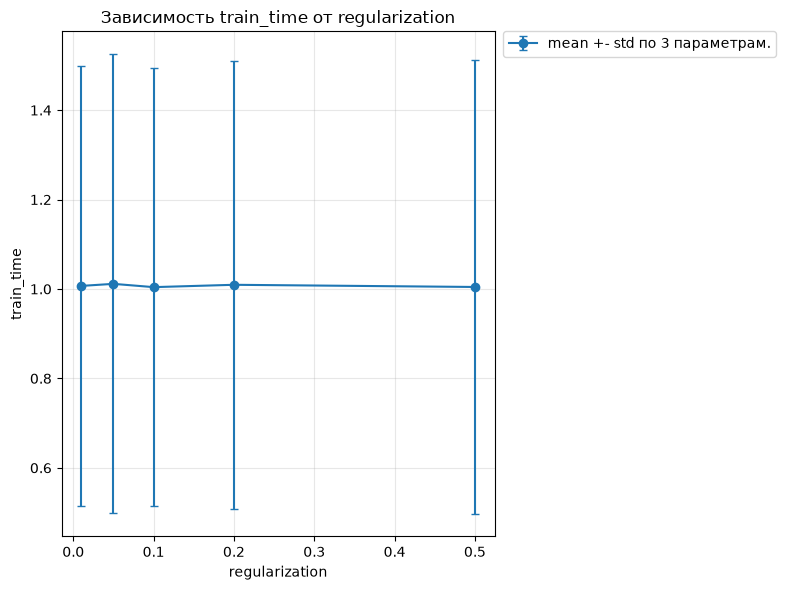

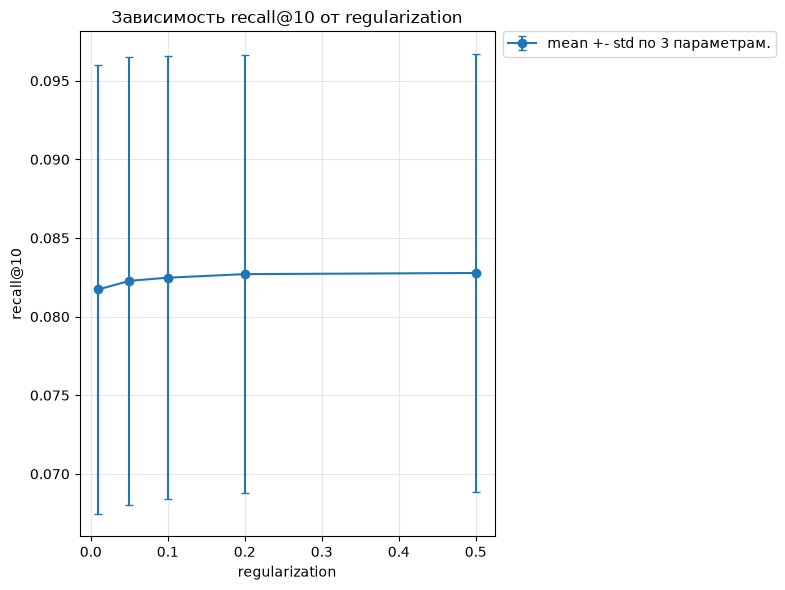

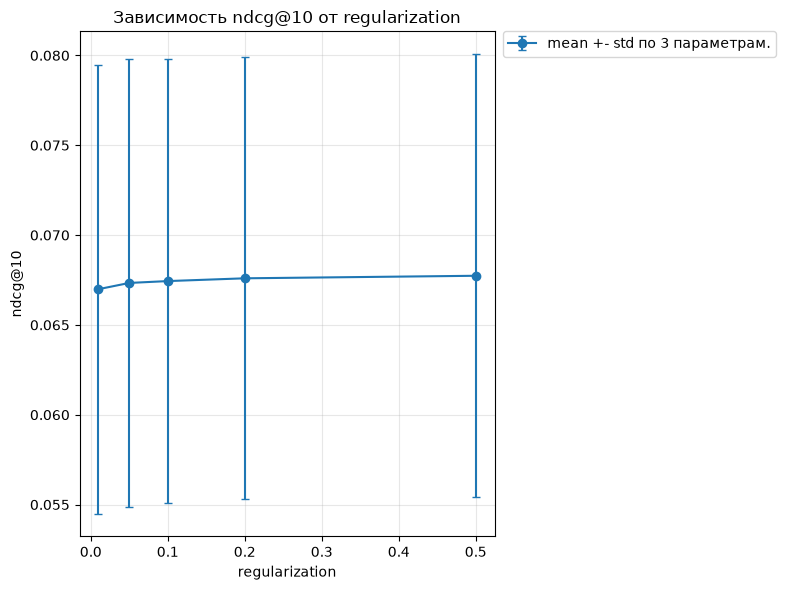

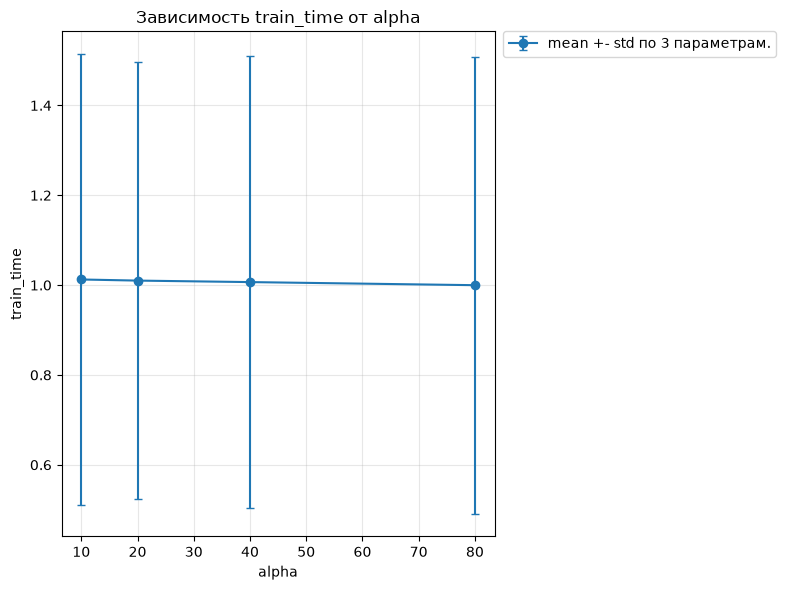

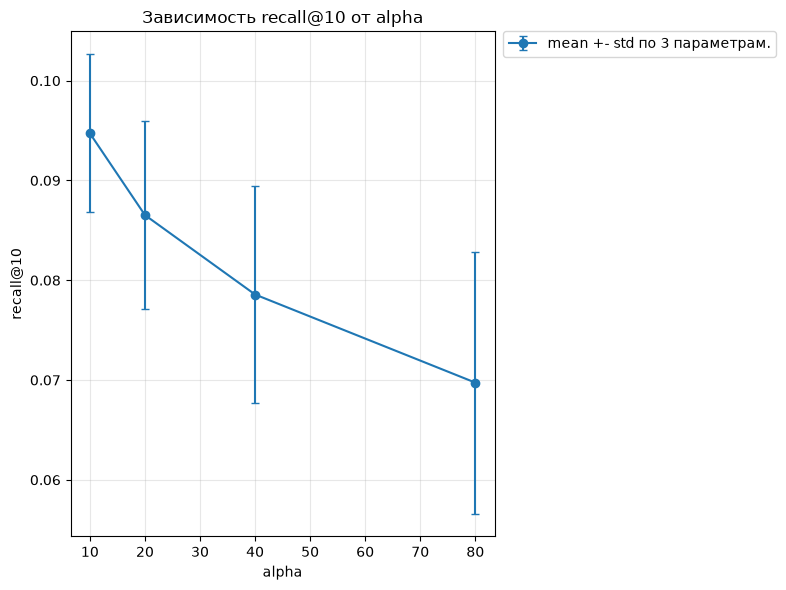

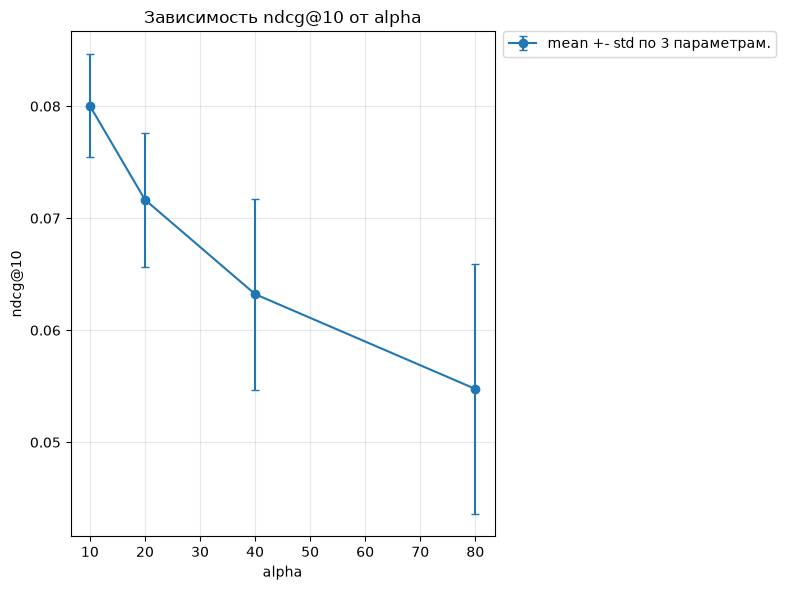

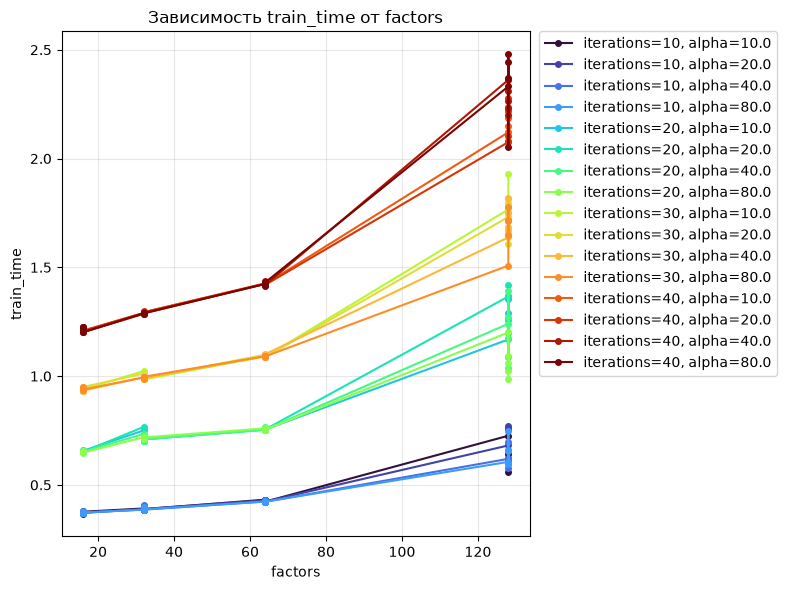

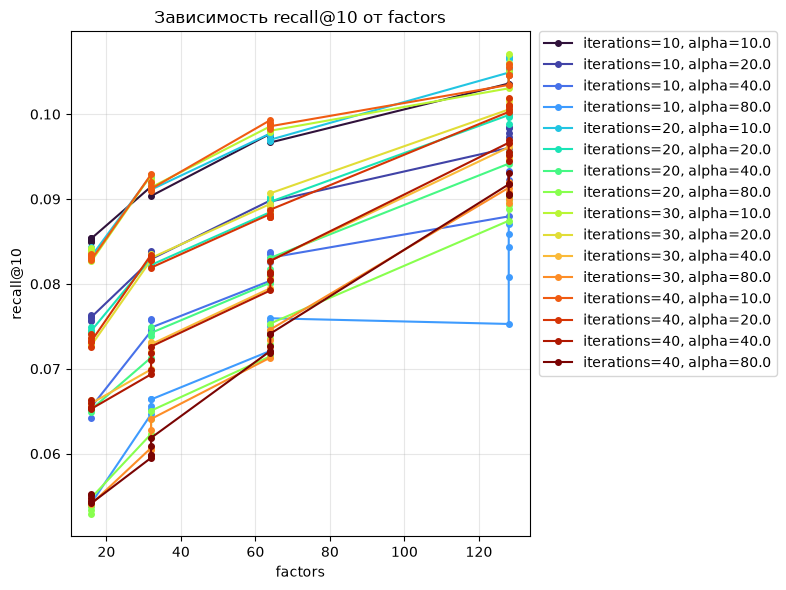

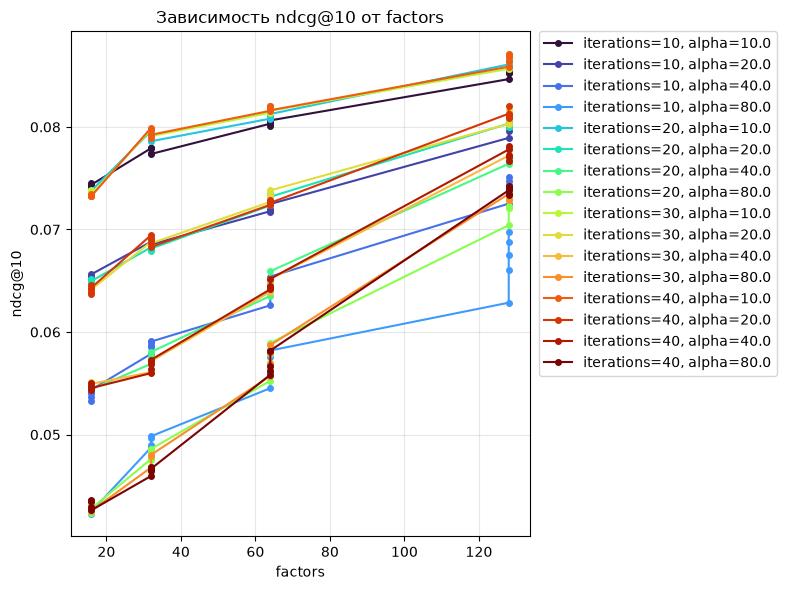

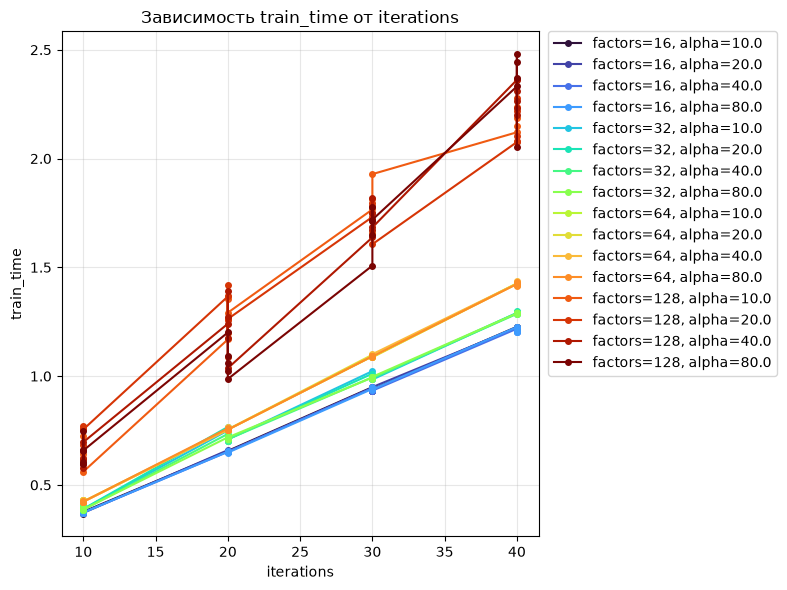

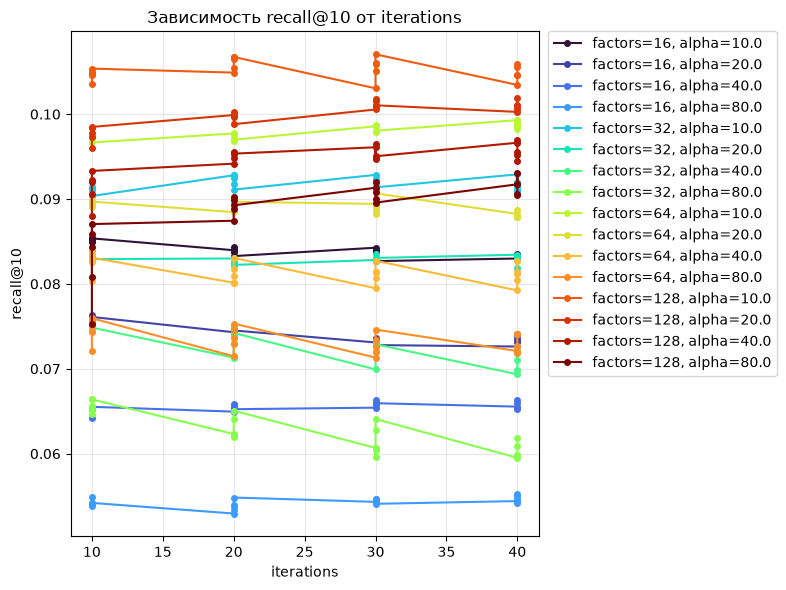

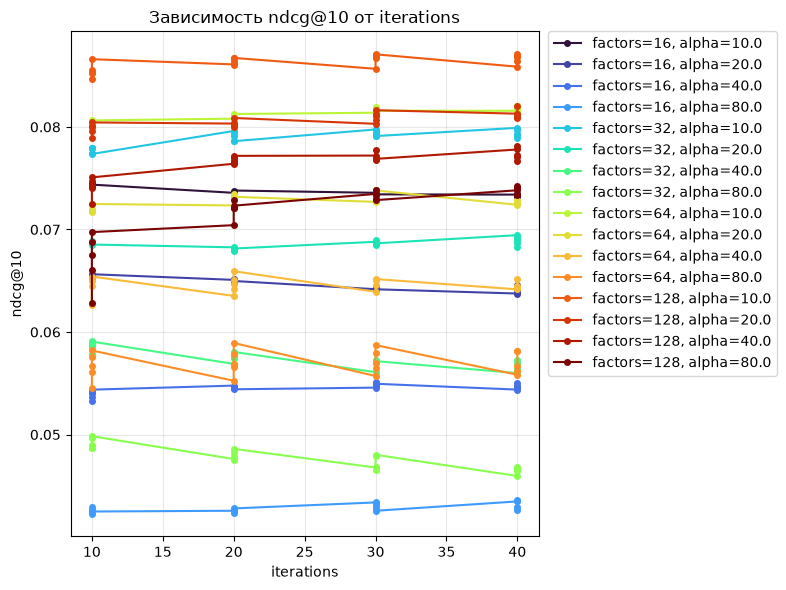

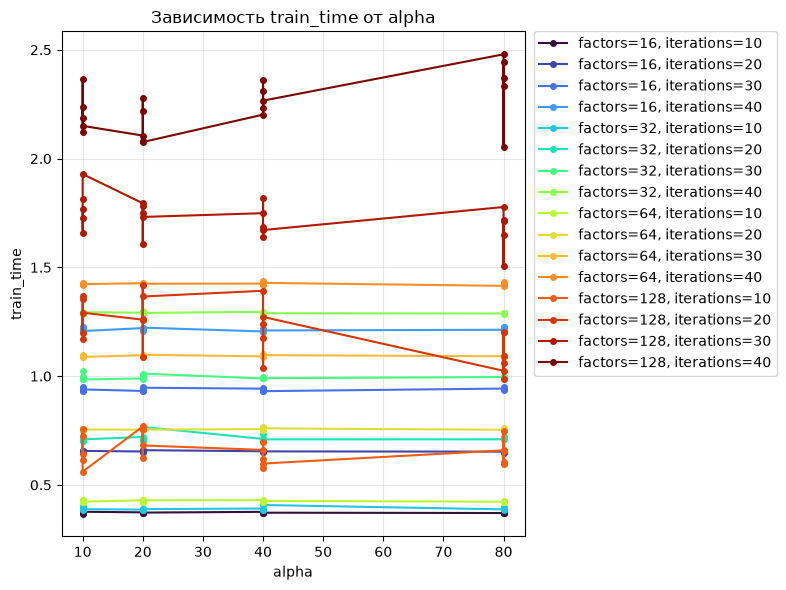

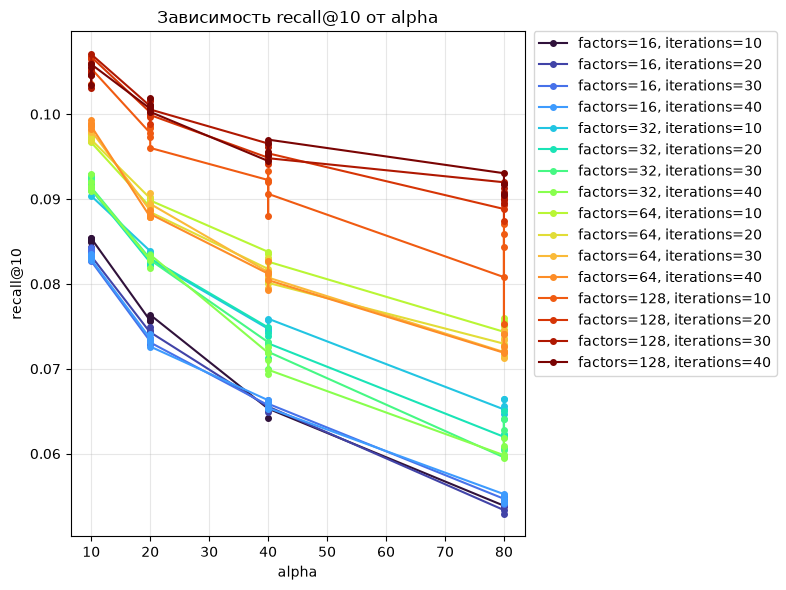

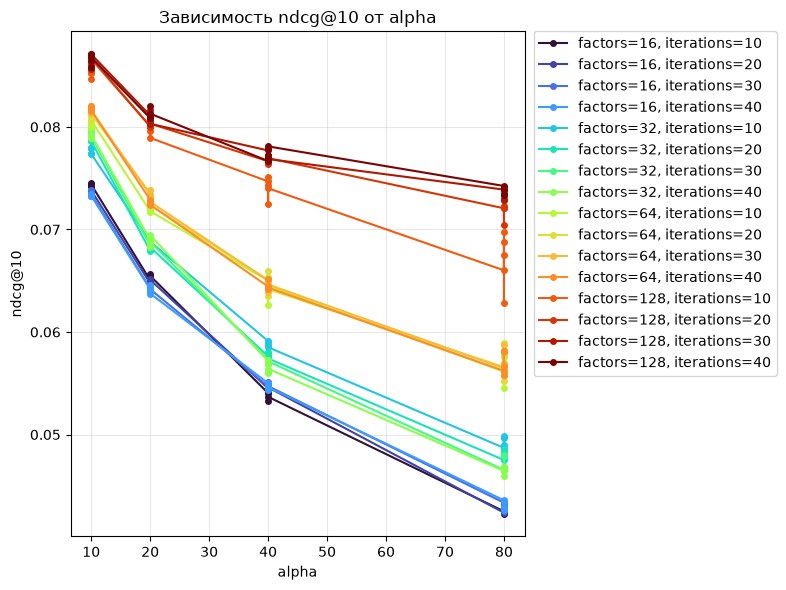

In [19]:
with open(IMPLICIT_ALS_PARAMS_SEARCH_PATH, "rb") as f:
    df_ImplicitALS = pickle.load(f)

show_graph(
    results_df=df_ImplicitALS,
    params=["factors", "iterations", "regularization", "alpha"],
    metrics=["train_time", "recall@10", "ndcg@10"],
    save_dir="graphs/implicitALS",
    max_lines=10
)

show_graph(
    results_df=df_ImplicitALS,
    params=["factors", "iterations", "alpha"],
    metrics=["train_time", "recall@10", "ndcg@10"],
    save_dir="graphs/implicitALS",
    max_lines=None
)

In [22]:
with open(IMPLICIT_ALS_PARAMS_SEARCH_PATH, "rb") as f:
    df_ImplicitALS = pickle.load(f)

df_ImplicitALS

,factors,iterations,regularization,alpha,train_time,pred_time,train_mem_delta,train_mem_peak,pred_mem_delta,pred_mem_peak,recall@10,ndcg@10
0,16,10,0.01,10.0,0.375091,1.085148,55.843750,1346.908854,0.348958,1346.908854,0.085119,0.074521
1,16,10,0.01,20.0,0.372866,1.057527,56.574219,1348.265625,0.144531,1348.265625,0.076354,0.065476
2,16,10,0.01,40.0,0.372588,1.063969,55.339844,1348.523438,0.019531,1348.523438,0.064217,0.053263
3,16,10,0.01,80.0,0.375752,1.051159,55.339844,1348.523438,0.020833,1348.523438,0.054067,0.042296
4,16,10,0.05,10.0,0.368489,1.035152,55.339844,1348.527344,0.019531,1348.527344,0.084928,0.074245
...,...,...,...,...,...,...,...,...,...,...,...,...
315,128,40,0.20,80.0,2.371108,1.605913,71.395833,1366.089844,0.019531,1366.089844,0.090644,0.073462
316,128,40,0.50,10.0,2.150350,1.591442,70.838542,1365.537760,0.019531,1365.537760,0.105875,0.086792
317,128,40,0.50,20.0,2.219320,1.630280,71.320312,1366.019531,0.019531,1366.019531,0.101949,0.082030
318,128,40,0.50,40.0,2.310251,1.628964,70.589844,1365.294271,0.019531,1365.294271,0.095208,0.077056


Оптимальный выбор параметров на валидационной выборке: `factors=128`, `iterations=40`, `regularization=0.2`, `alpha=10.0`.

На графике зависимости `NDCG@10` от `factors` видно, что 128 факторов дают прирост качества по сравнению с 16, 32 и 64 - модель лучше улавливает скрытые связи между пользователями и фильмами за счет более большого представления скрытых векторов. Для задач ранжирования (рекомендаций) прирост `NDCG` наиболее важен для бизнеса, поэтому имеет смысл брать максимальное значение из рассмотренных.

Для 128 факторов график `NDCG@10` от `iterations` показывает, что модель демонстрирует лучшие метрики при высоком значении `iterations=40`. Увеличение числа итераций позволяет ALS лучше сойтись к оптимальному разложению, а на 40 итерациях еще не наблюдается выраженного переобучения, качество продолжает расти.

Влияние `regularization` на `NDCG@10` выражено слабо. Слишком малый коэффициент регуляризации повышает риск переобучения, поэтому оптимальным выбрано значение `0.2`, которое снижает риск переобучения на разреженных данных без потери качества.

По графику `NDCG@10` от `alpha` видно, что качество монотонно убывает с ростом `alpha` и достигает максимума в районе `alpha=10.0`. Поскольку модель обучается только на положительных взаимодействиях (`rating >= 3.5`), дальнейшее увеличение `alpha` снижает метрику: слишком большой вес уверенности начинает усиливать смещение в сторону популярных оценок, тогда как значение 10.0 обеспечивает оптимальный баланс.

In [25]:
def model_factory():
    return ImplicitALS(factors=128, iterations=40, regularization=0.2, alpha=10.0)

train_val = pd.concat([train, val], ignore_index=True)

results = run_benchmark(model_factory, train_val, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 1.982 сек.
[memory_usage] Обучение implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 84.508 MB
[timer] Выдача рекомендаций implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 1.632 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 0.020 MB
[timer] Обучение implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 2.252 сек.
[memory_usage] Обучение implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 78.223 MB
[timer] Выдача рекомендаций implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 1.620 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 0.023 MB
[timer] Обучение implicit ALS(factors=128, iterations=40, regularization=0.2, alpha=10.0): 2.628 сек.
[memory_usage] О

| Алгоритм | Параметры | Train time, сек | Predict time, сек | Прирост RSS при обучении, МБ | Пиковый RSS при обучении, МБ | Прирост RSS при предсказании, МБ | Пиковый RSS при предсказании, МБ | Recall@10 | NDCG@10 |
|----------|-----------|-----------------|-------------------|------------------------------|------------------------------|----------------------------------|----------------------------------|-----------|---------|
| UserBasedCF | top_k=5 | 2.596 | 2.988 | 1260.95 | 2511.81 | 552.14 | 2511.81 | 0.0406 | 0.0466 |
| ImplicitALS | factors=128, iterations=40, regularization=0.2, alpha=10.0 | 2.288 | 1.633 | 83.19 | 1384.21 | 0.02 | 1384.21 | 0.0873 | 0.1118 |

На отложенной тестовой выборке `ImplicitALS` превосходит `UserBasedCF` по всем измеряемым метрикам: показывает более высокий `NDCG@10` (0.1118 против 0.0466, в 2.4 раза выше) и более высокий `Recall@10` (0.0873 против 0.0406, в 2.15 раза выше) за счет исключения уже оцененных фильмов при выдаче рекомендаций и обучения только на положительных оценках.

При этом `ImplicitALS` выигрывает по стоимости эксплуатации: обучение быстрее (2.288 с против 2.596 с), предсказание быстрее почти в 2 раза, а прирост RSS при обучении меньше в 15 раз, при предсказании тоже намного меньше. Поэтому `ALS` более предпочтительный при масштабировании на 10M/32M.